<a href="https://colab.research.google.com/github/Ankitojha-mac/Laptop_Price_prediction/blob/main/code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("laptop_price.csv" , encoding="latin1")

In [3]:
data

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,1316,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,638.00
1299,1317,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,1499.00
1300,1318,Lenovo,IdeaPad 100S-14IBR,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,229.00
1301,1319,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,764.00


In [4]:
data.isnull().sum()

,0
laptop_ID,0
Company,0
Product,0
TypeName,0
Inches,0
ScreenResolution,0
Cpu,0
Ram,0
Memory,0
Gpu,0


In [5]:
data = data.drop("laptop_ID" , axis = 1)

In [6]:
data["Ram"]=data["Ram"].str.replace('GB','')
data["Weight"] = data["Weight"].str.replace('kg','')


In [7]:
data.head()

,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60


In [8]:
data['Ram'] = data['Ram'].astype('float64')
data['Weight'] = data['Weight'].astype('float64')


In [9]:
data["Company"].value_counts()

,count
Company,
Dell,297
Lenovo,297
HP,274
Asus,158
Acer,103
MSI,54
Toshiba,48
Apple,21
Samsung,9


In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1303 non-null   object 
 1   Product           1303 non-null   object 
 2   TypeName          1303 non-null   object 
 3   Inches            1303 non-null   float64
 4   ScreenResolution  1303 non-null   object 
 5   Cpu               1303 non-null   object 
 6   Ram               1303 non-null   float64
 7   Memory            1303 non-null   object 
 8   Gpu               1303 non-null   object 
 9   OpSys             1303 non-null   object 
 10  Weight            1303 non-null   float64
 11  Price_euros       1303 non-null   float64
dtypes: float64(4), object(8)
memory usage: 122.3+ KB


<Axes: xlabel='Company'>

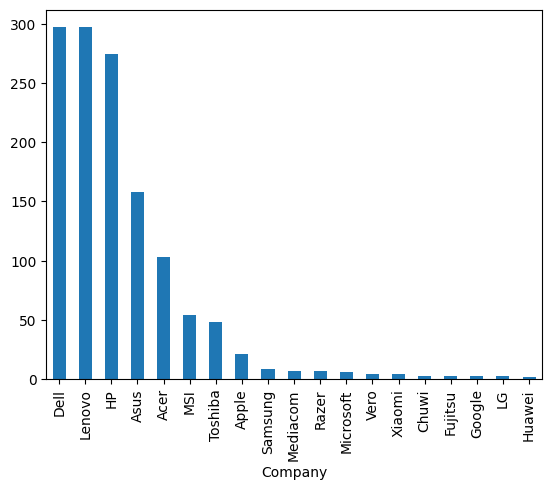

In [11]:
data["Company"].value_counts().plot(kind='bar')

In [12]:
data["TypeName"].value_counts()

,count
TypeName,
Notebook,727
Gaming,205
Ultrabook,196
2 in 1 Convertible,121
Workstation,29
Netbook,25


<Axes: xlabel='TypeName'>

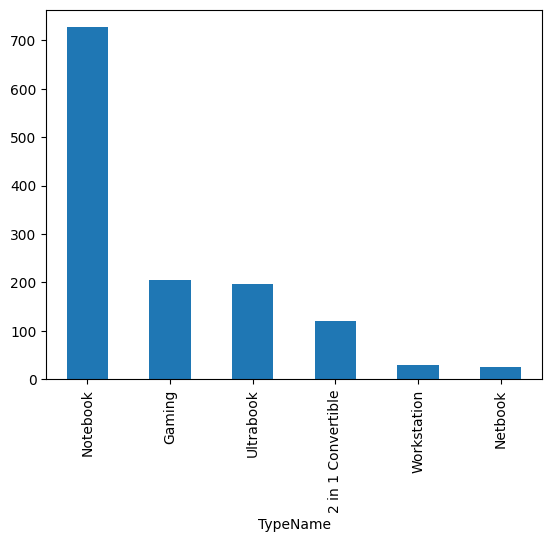

In [13]:
data["TypeName"].value_counts().plot(kind='bar')

In [14]:
data.columns

Index(['Company', 'Product', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu',
       'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price_euros'],
      dtype='object')

In [15]:
data = pd.get_dummies(data,columns = ["TypeName"] , dtype = int , drop_first = True)

In [16]:
data = pd.get_dummies(data , columns = ["Company"] , dtype = int , drop_first = True )

In [17]:
data

,Product,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros,...,Company_LG,Company_Lenovo,Company_MSI,Company_Mediacom,Company_Microsoft,Company_Razer,Company_Samsung,Company_Toshiba,Company_Vero,Company_Xiaomi
0,MacBook Pro,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8.0,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,...,0,0,0,0,0,0,0,0,0,0
1,Macbook Air,13.3,1440x900,Intel Core i5 1.8GHz,8.0,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,...,0,0,0,0,0,0,0,0,0,0
2,250 G6,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8.0,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,...,0,0,0,0,0,0,0,0,0,0
3,MacBook Pro,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16.0,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,...,0,0,0,0,0,0,0,0,0,0
4,MacBook Pro,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8.0,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,Yoga 500-14ISK,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4.0,128GB SSD,Intel HD Graphics 520,Windows 10,1.80,638.00,...,0,1,0,0,0,0,0,0,0,0
1299,Yoga 900-13ISK,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16.0,512GB SSD,Intel HD Graphics 520,Windows 10,1.30,1499.00,...,0,1,0,0,0,0,0,0,0,0
1300,IdeaPad 100S-14IBR,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2.0,64GB Flash Storage,Intel HD Graphics,Windows 10,1.50,229.00,...,0,1,0,0,0,0,0,0,0,0
1301,15-AC110nv (i7-6500U/6GB/1TB/Radeon,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6.0,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19,764.00,...,0,0,0,0,0,0,0,0,0,0


In [18]:
data = pd.get_dummies(data , columns = ["Product"] , dtype = int , drop_first = True )
data = pd.get_dummies(data , columns = ["ScreenResolution"] , dtype = int , drop_first = True )
data = pd.get_dummies(data , columns = ["Cpu"] , dtype = int , drop_first = True )
data = pd.get_dummies(data , columns = ["Memory"] , dtype = int , drop_first = True )
data = pd.get_dummies(data , columns = ["Gpu"] , dtype = int , drop_first = True )
data = pd.get_dummies(data , columns = ["OpSys"] , dtype = int , drop_first = True )

In [19]:
data

,Inches,Ram,Weight,Price_euros,TypeName_Gaming,TypeName_Netbook,TypeName_Notebook,TypeName_Ultrabook,TypeName_Workstation,Company_Apple,...,Gpu_Nvidia Quadro M620,Gpu_Nvidia Quadro M620M,OpSys_Chrome OS,OpSys_Linux,OpSys_Mac OS X,OpSys_No OS,OpSys_Windows 10,OpSys_Windows 10 S,OpSys_Windows 7,OpSys_macOS
0,13.3,8.0,1.37,1339.69,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,1
1,13.3,8.0,1.34,898.94,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,1
2,15.6,8.0,1.86,575.00,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,15.4,16.0,1.83,2537.45,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,1
4,13.3,8.0,1.37,1803.60,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,14.0,4.0,1.80,638.00,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
1299,13.3,16.0,1.30,1499.00,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
1300,14.0,2.0,1.50,229.00,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0
1301,15.6,6.0,2.19,764.00,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0


In [20]:
x=data.drop("Price_euros" , axis = 1)
y =data["Price_euros"]

In [21]:
from sklearn.model_selection import train_test_split

In [22]:
x_train , x_test , y_train , y_test = train_test_split(x,y,test_size =0.2 ,random_state = 42)

In [23]:
from sklearn.preprocessing import StandardScaler
SS = StandardScaler()
x_train_scaled = SS.fit_transform(x_train)
x_test_scaled = SS.fit_transform(x_test)

In [24]:
from sklearn.linear_model import LinearRegression
LR = LinearRegression()
LR.fit(x_train_scaled , y_train)

LinearRegression()

In [25]:
y_pred = LR.predict(x_test_scaled)

In [26]:
from sklearn.metrics import mean_squared_error , r2_score , mean_absolute_error
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test,y_pred)

In [27]:
print(mse)
print(r2)

111130.28628108311
0.7812079486653984


In [28]:
from sklearn.neighbors import KNeighborsRegressor
knn = KNeighborsRegressor(n_neighbors=3)
knn.fit(x_train, y_train)


KNeighborsRegressor(n_neighbors=3)

In [29]:
y_pred = knn.predict(x_test)

In [30]:

print("MAE:", mean_absolute_error(y_test, y_pred))
print("R² Score:", r2_score(y_test, y_pred))

MAE: 193.88694763729245
R² Score: 0.803249562056199


In [31]:
from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor(max_depth=10,random_state=42)
dt.fit(x_train, y_train)

DecisionTreeRegressor(max_depth=10, random_state=42)

In [32]:
y_pred_dt = dt.predict(x_test)

In [33]:
print("R2 Score:", r2_score(y_test, y_pred_dt))
print("MAE:", mean_absolute_error(y_test, y_pred_dt))


R2 Score: 0.726455310442987
MAE: 249.19694583978585


In [34]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=300,random_state=42,max_depth=20)
rf.fit(x_train, y_train)

RandomForestRegressor(max_depth=20, n_estimators=300, random_state=42)

In [35]:
y_pred_rf = rf.predict(x_test)
print("R2 Score:", r2_score(y_test, y_pred_rf))
print("MAE:", mean_absolute_error(y_test, y_pred_rf))

R2 Score: 0.8128657046202243
MAE: 186.46087081485183


In [46]:
import xgboost as xgb
import re

regex = re.compile(r"[\[\]<]")
x_train_clean = x_train.copy()
x_test_clean = x_test.copy()

x_train_clean.columns = [regex.sub("_", col) for col in x_train_clean.columns]
x_test_clean.columns = [regex.sub("_", col) for col in x_test_clean.columns]


xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb_model.fit(x_train_clean, y_train)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, num_parallel_tree=None, ...)

In [45]:

y_pred_xgb = xgb_model.predict(x_test_clean)
xgb_r2 = r2_score(y_test, y_pred_xgb)
xgb_mae = mean_absolute_error(y_test, y_pred_xgb)

print(f"XGBoost R2 Score: {xgb_r2:.4f}")
print(f"XGBoost MAE: {xgb_mae:.4f}")

XGBoost R2 Score: 0.8409
XGBoost MAE: 170.1750
